# 03a · A sarcasm direction in the residual stream

Phase 2 showed that the mechanism is **distributed**: no small circuit answers like the model. Here we ask what the
full model **represents**, independently of any circuit: is there a direction in the residual stream that encodes
"this is sarcastic", from which layer, and is it causal?

1. **Probes per layer** (last token): a linear classifier S vs (P, N), trained on discovery prompts and tested on
   held-out prompts with **new phrases** and a **new sentence frame**. Same for two controls: phrase polarity
   (positive vs negative phrase) and situation valence (pleasant vs unpleasant).
2. **More than sentiment?** Sarcasm = positive phrase AND unpleasant situation, which a linear probe could read from
   the two sentiment features alone. We compare (a) the full probe, (b) a probe that only sees the projections on
   the phrase and situation directions, (c) the full probe after removing those two directions.
3. **Steering (causal test)**: add α · (mean S − mean P/N) to the residual stream at the last token at one layer:
   do non-sarcastic prompts become "Yes" (α > 0) and sarcastic ones "No" (α < 0)? Control: a random direction of
   the same length.
4. **Who writes the direction**: the projection of every head's and MLP's output on the direction, S vs P/N, and
   whether these components are in the ACDC circuits.
5. **Your own sentences**: where they fall on the direction (0 = like an average non-sarcastic prompt,
   1 = like an average sarcastic prompt).

**Runtime:** T4 is enough; about 20–30 minutes (the residual streams of all prompts are saved on Drive, ~0.6 GB).

## Setup

In [1]:
# Get (or update) the code from GitHub
import os, sys
REPO = "https://github.com/vasilis-pantzos/sarcasm-proposal.git"
ROOT = "/content/sarcasm-proposal"
if not os.path.exists(ROOT):
    !git clone -q {REPO} {ROOT}
else:
    !git -C {ROOT} pull -q
os.chdir(ROOT)
sys.path.insert(0, ROOT)
%pip install -q -U accelerate bitsandbytes

In [2]:
import os, json, time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from src.model import load_model, model_info, DEV_MODEL, MAIN_MODEL
from src.prompts import load_dataset, encode, chat_text, data_tag
from src.direction import collect_resid, steer_d, component_writes, logreg_predict
from src.utils import mount_drive, results_dir, cached, set_seed

# ---------------- settings ----------------
MODEL = MAIN_MODEL          # DEV_MODEL (3B) for quick tests
DATA = "v2"                 # dataset: "v1" (pilot) or "v2"
STEER_LAYERS = [6, 10, 12, 14, 16, 18, 20, 22, 24]
ALPHAS = [-2, -1, -0.5, 0, 0.5, 1, 2]       # multiples of (mean S - mean P/N)
N_STEER = 40                # held-out triples per held-out group for steering
N_WRITE = 100               # discovery triples for "who writes the direction"
# ------------------------------------------
TAG_MODEL = MODEL.split("/")[-1]
TAG = TAG_MODEL + data_tag(DATA)
SUB = f"03a_direction/{TAG}"
mount_drive()
print("results go to:", results_dir(SUB))
set_seed(0)

Mounted at /content/drive
results go to: /content/drive/MyDrive/sarcasm/03a_direction/Qwen2.5-7B-Instruct_data-v2


In [3]:
t0 = time.time()
model, tok = load_model(MODEL)
INFO = model_info(model)
L, H = INFO["n_layers"], INFO["n_heads"]
print(MODEL, INFO, f"loaded in {(time.time() - t0) / 60:.1f} min")

df = load_dataset(DATA).sort_values(["split", "triple_id", "condition"]).reset_index(drop=True)
df["group"] = [s if s == "discovery" else f"heldout ({t})" for s, t in zip(df.split, df.heldout_type)]
GROUPS = [g for g in ["discovery", "heldout (phrase)", "heldout (frame)"] if g in set(df.group)]
IDS = [encode(tok, r).ids for r in df.itertuples()]
TRAIN = (df.group == "discovery").values
LABELS = {
    "sarcasm (S vs P, N)": (df.condition == "S").values,
    "phrase polarity (positive)": (df.frame_type == "positive").values,
    "situation valence (pleasant)": (df.situation_type == "pleasant").values,
}
print({g: int((df.group == g).sum()) for g in GROUPS}, "prompts")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen/Qwen2.5-7B-Instruct {'n_layers': 28, 'n_heads': 28, 'n_kv_heads': 4, 'd_model': 3584, 'head_dim': 128} loaded in 1.3 min
{'discovery': 1890, 'heldout (phrase)': 630, 'heldout (frame)': 210} prompts


## Residual stream at the last token, all layers

In [4]:
t0 = time.time()
X, D_FULL = cached("resid_last_token", lambda: collect_resid(model, tok, IDS), sub=SUB)
print("X", X.shape, X.dtype, f"| {(time.time() - t0) / 60:.1f} min")
df["d full"] = D_FULL

  340/2730 prompts
  657/2730 prompts
  962/2730 prompts
  1282/2730 prompts
  1608/2730 prompts
  1926/2730 prompts
  2246/2730 prompts
  2578/2730 prompts
[saved]  /content/drive/MyDrive/sarcasm/03a_direction/Qwen2.5-7B-Instruct_data-v2/resid_last_token.pt
X (2730, 29, 3584) float16 | 1.1 min


## 1 · Probes per layer

Logistic regression (L2, fitted on the GPU) on the standardised residual stream (trained on discovery), balanced accuracy on each group
(0.5 = chance). Held-out groups are never seen in training.

  sarcasm (S vs P, N): done
  phrase polarity (positive): done
  situation valence (pleasant): done
[saved]  /content/drive/MyDrive/sarcasm/03a_direction/Qwen2.5-7B-Instruct_data-v2/probes.pt
0.7 min


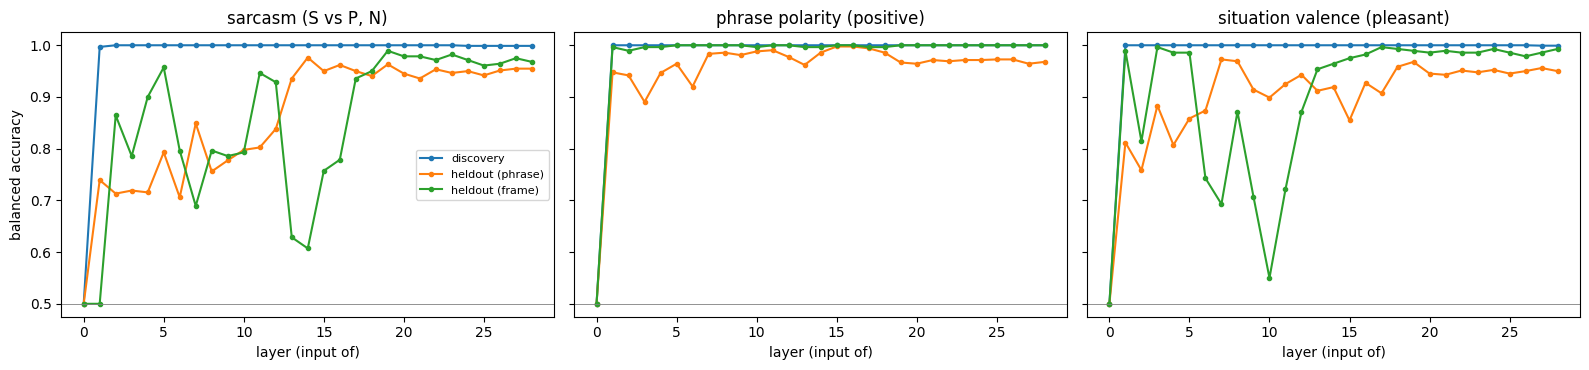

best layer for sarcasm on held-out prompts: 19 (balanced accuracy {'discovery': np.float64(1.0), 'heldout (phrase)': np.float64(0.963), 'heldout (frame)': np.float64(0.989)})


In [5]:
def bal_acc(pred, y):
    return 0.5 * (pred[y].mean() + (~pred[~y]).mean())

def layer_feats(l):
    Z = X[:, l].astype(np.float32)
    mu, sd = Z[TRAIN].mean(0), Z[TRAIN].std(0) + 1e-6
    return (Z - mu) / sd

def run_probes():
    out = {}
    for name, y in LABELS.items():
        acc = np.zeros((L + 1, len(GROUPS)))
        for l in range(L + 1):
            Z = layer_feats(l)
            pred = logreg_predict(Z[TRAIN], y[TRAIN], Z)
            for j, g in enumerate(GROUPS):
                m = (df.group == g).values
                acc[l, j] = bal_acc(pred[m], y[m])
        out[name] = acc
        print(f"  {name}: done")
    return out

t0 = time.time()
PROBE = cached("probes", run_probes, sub=SUB)
print(f"{(time.time() - t0) / 60:.1f} min")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, (name, acc) in zip(axes, PROBE.items()):
    for j, g in enumerate(GROUPS):
        ax.plot(acc[:, j], marker="o", ms=3, label=g)
    ax.axhline(0.5, c="gray", lw=0.6); ax.set_title(name); ax.set_xlabel("layer (input of)")
axes[0].set_ylabel("balanced accuracy"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "probes_per_layer.png"), dpi=150); plt.show()

sarc = PROBE["sarcasm (S vs P, N)"]
held = [j for j, g in enumerate(GROUPS) if g != "discovery"]
L_STAR = int(np.argmax(sarc[:L, held].mean(1)))      # an input of a layer (0 .. L-1), so we can steer there
print(f"best layer for sarcasm on held-out prompts: {L_STAR} "
      f"(balanced accuracy {dict(zip(GROUPS, sarc[L_STAR].round(3)))})")

## 2 · More than sentiment?

Per layer: the sarcasm probe (a) on everything, (b) on only the two projections onto the phrase direction and the
situation direction (difference of means on discovery), (c) on everything after removing those two directions.
If (a) ≫ (b) and (c) stays high, the model represents sarcasm with more than the two sentiment features.

/tmp/ipykernel_3083/3884803697.py:14: RuntimeWarning: invalid value encountered in scalar divide
  cos[l] = [v @ u_p / np.linalg.norm(v) / np.linalg.norm(u_p), v @ u_s / np.linalg.norm(v) / np.linalg.norm(u_s)]


[saved]  /content/drive/MyDrive/sarcasm/03a_direction/Qwen2.5-7B-Instruct_data-v2/sentiment_test.pt


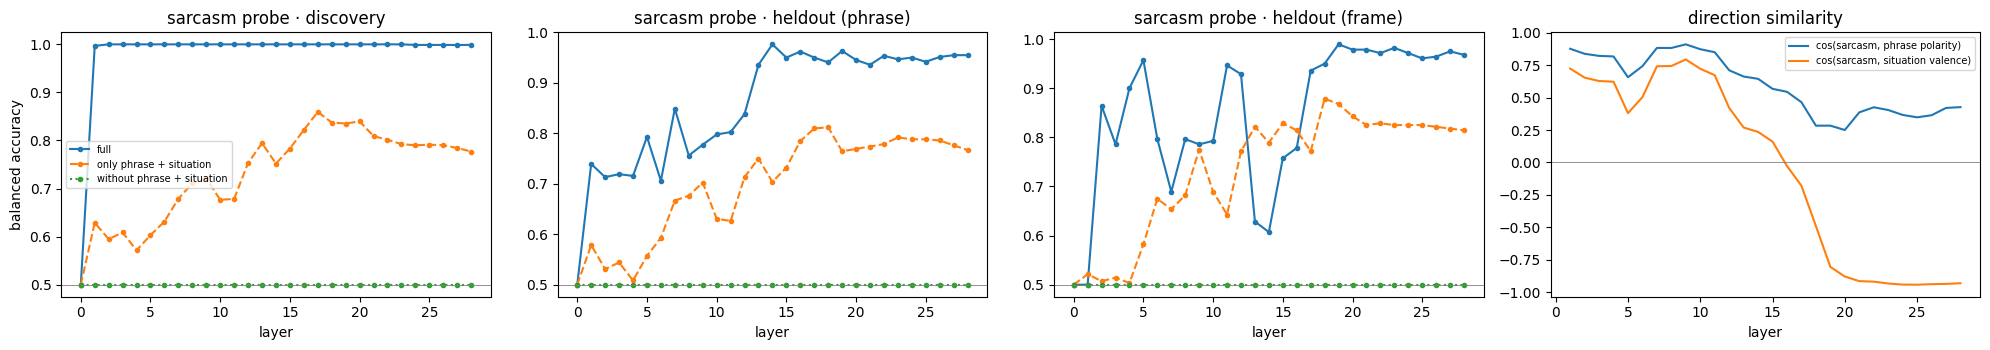

layer 19: {'full': {'discovery': np.float64(1.0), 'heldout (phrase)': np.float64(0.963), 'heldout (frame)': np.float64(0.989)}, 'only phrase + situation': {'discovery': np.float64(0.835), 'heldout (phrase)': np.float64(0.764), 'heldout (frame)': np.float64(0.868)}, 'without phrase + situation': {'discovery': np.float64(0.5), 'heldout (phrase)': np.float64(0.5), 'heldout (frame)': np.float64(0.5)}}


In [6]:
def mean_dir(l, y):
    Z = X[:, l].astype(np.float32)
    return Z[TRAIN & y].mean(0) - Z[TRAIN & ~y].mean(0)

def sentiment_test():
    y = LABELS["sarcasm (S vs P, N)"]
    res = {k: np.zeros((L + 1, len(GROUPS))) for k in ["full", "only phrase + situation", "without phrase + situation"]}
    cos = np.zeros((L + 1, 2))
    for l in range(L + 1):
        Z = X[:, l].astype(np.float32)
        u_p = mean_dir(l, LABELS["phrase polarity (positive)"])
        u_s = mean_dir(l, LABELS["situation valence (pleasant)"])
        v = mean_dir(l, y)
        cos[l] = [v @ u_p / np.linalg.norm(v) / np.linalg.norm(u_p), v @ u_s / np.linalg.norm(v) / np.linalg.norm(u_s)]
        Q, _ = np.linalg.qr(np.stack([u_p, u_s], 1))                  # orthonormal basis of the two directions
        two = Z @ Q
        Zr = Z - (Z @ Q) @ Q.T
        for k, F in [("full", Z), ("only phrase + situation", two), ("without phrase + situation", Zr)]:
            mu, sd = F[TRAIN].mean(0), F[TRAIN].std(0) + 1e-6
            Fz = (F - mu) / sd
            pred = logreg_predict(Fz[TRAIN], y[TRAIN], Fz)
            for j, g in enumerate(GROUPS):
                m = (df.group == g).values
                res[k][l, j] = bal_acc(pred[m], y[m])
    return res, cos

SENT, COS = cached("sentiment_test", sentiment_test, sub=SUB)
fig, axes = plt.subplots(1, len(GROUPS) + 1, figsize=(5 * (len(GROUPS) + 1), 3.6))
for ax, (j, g) in zip(axes, enumerate(GROUPS)):
    for k, ls in [("full", "-"), ("only phrase + situation", "--"), ("without phrase + situation", ":")]:
        ax.plot(SENT[k][:, j], ls, marker="o", ms=3, label=k)
    ax.axhline(0.5, c="gray", lw=0.6); ax.set_title(f"sarcasm probe · {g}"); ax.set_xlabel("layer")
axes[0].set_ylabel("balanced accuracy"); axes[0].legend(fontsize=7)
axes[-1].plot(COS[:, 0], label="cos(sarcasm, phrase polarity)"); axes[-1].plot(COS[:, 1], label="cos(sarcasm, situation valence)")
axes[-1].axhline(0, c="gray", lw=0.6); axes[-1].set_title("direction similarity"); axes[-1].set_xlabel("layer"); axes[-1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "more_than_sentiment.png"), dpi=150); plt.show()
print(f"layer {L_STAR}:", {k: dict(zip(GROUPS, v[L_STAR].round(3))) for k, v in SENT.items()})

## 3 · Steering (causal test)

At the input of a layer, add α · v to the residual stream at the last token, v = mean(S) − mean(P, N) at that layer
(discovery). α = +1 moves an average non-sarcastic prompt to the average sarcastic one. Held-out prompts only.

240 held-out prompts for steering
  layer 6 done
  layer 10 done
  layer 12 done
  layer 14 done
  layer 16 done
  layer 18 done
  layer 20 done
  layer 22 done
  layer 24 done
[saved]  /content/drive/MyDrive/sarcasm/03a_direction/Qwen2.5-7B-Instruct_data-v2/steering_6_10_12_14_16_18_20_22_24_n40_Lstar19.pt
6.8 min


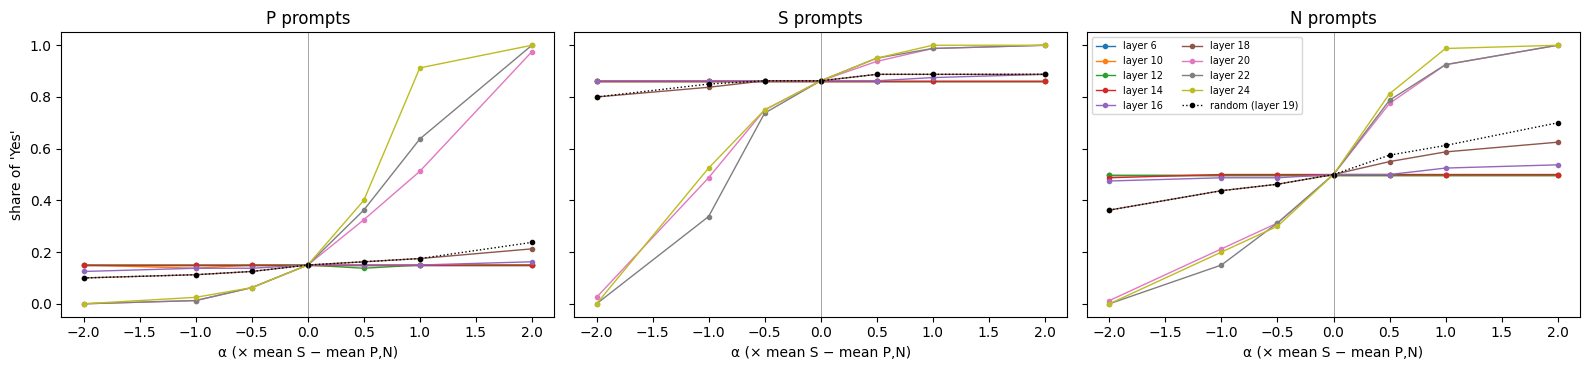

Yes rate P             Yes rate S             Yes rate N           
alpha        -1.0   0.0   1.0       -1.0   0.0   1.0       -1.0  0.0   1.0
layer                                                                     
6            0.15  0.15  0.15       0.86  0.86  0.86       0.50  0.5  0.50
10           0.14  0.15  0.15       0.86  0.86  0.86       0.50  0.5  0.50
12           0.15  0.15  0.15       0.86  0.86  0.86       0.50  0.5  0.50
14           0.15  0.15  0.15       0.86  0.86  0.86       0.50  0.5  0.50
16           0.14  0.15  0.15       0.86  0.86  0.88       0.49  0.5  0.52
18           0.11  0.15  0.18       0.84  0.86  0.89       0.44  0.5  0.59
20           0.01  0.15  0.51       0.49  0.86  0.99       0.21  0.5  0.92
22           0.01  0.15  0.64       0.34  0.86  0.99       0.15  0.5  0.92
24           0.02  0.15  0.91       0.52  0.86  1.00       0.20  0.5  0.99
random       0.11  0.15  0.18       0.85  0.86  0.89       0.44  0.5  0.61

In [7]:
rng = np.random.default_rng(0)
steer_idx = []
for g in GROUPS[1:]:
    tids = rng.choice(df[df.group == g].triple_id.unique(), min(N_STEER, df[df.group == g].triple_id.nunique()), replace=False)
    steer_idx += list(df.index[df.triple_id.isin(tids)])
SD = df.loc[steer_idx]
print(f"{len(SD)} held-out prompts for steering")

V = {l: mean_dir(l, LABELS["sarcasm (S vs P, N)"]) for l in range(L + 1)}

def run_steering():
    out = {}
    for l in STEER_LAYERS:
        out[l] = steer_d(model, tok, [IDS[i] for i in steer_idx], l, V[l], ALPHAS)
        print(f"  layer {l} done")
    r = np.random.default_rng(1).standard_normal(V[L_STAR].shape).astype(np.float32)
    r *= np.linalg.norm(V[L_STAR]) / np.linalg.norm(r)
    out["random"] = steer_d(model, tok, [IDS[i] for i in steer_idx], L_STAR, r, ALPHAS)
    return out

t0 = time.time()
STEER = cached(f"steering_{'_'.join(map(str, STEER_LAYERS))}_n{N_STEER}_Lstar{L_STAR}", run_steering, sub=SUB)
print(f"{(time.time() - t0) / 60:.1f} min")

cond = SD.condition.values
a0 = ALPHAS.index(0)
rows = []
for key, dd in STEER.items():
    for k, al in enumerate(ALPHAS):
        rows.append(dict(layer=key, alpha=al,
                         **{f"Yes rate {c}": float((dd[k][cond == c] > 0).mean()) for c in "PSN"},
                         **{f"mean d {c}": float(dd[k][cond == c].mean()) for c in "PSN"}))
ST = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, c in zip(axes, "PSN"):
    for key in STEER:
        s = ST[ST.layer == key]
        ax.plot(s.alpha, s[f"Yes rate {c}"], marker="o", ms=3, label=f"layer {key}" if key != "random" else f"random (layer {L_STAR})",
                lw=2.5 if key == L_STAR else 1, ls=":" if key == "random" else "-", color="black" if key == "random" else None)
    ax.set_title(f"{c} prompts"); ax.set_xlabel("α (× mean S − mean P,N)"); ax.axvline(0, c="gray", lw=0.5)
axes[0].set_ylabel("share of 'Yes'"); axes[-1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "steering.png"), dpi=150); plt.show()

summary = ST[ST.alpha.isin([-1, 0, 1])].pivot(index="layer", columns="alpha", values=["Yes rate P", "Yes rate S", "Yes rate N"])
display(summary.round(2))

## 4 · Who writes the direction

At the best layer `L_STAR`, the projection of every head's and MLP's output (last token) on the unit sarcasm
direction; score = mean over S − mean over P, N. Sanity: embedding + all heads + all MLPs = the residual stream.
Components are marked if they have edges in the ACDC circuits (v3b τ = 0) found on v2 and on v1.

[saved]  /content/drive/MyDrive/sarcasm/03a_direction/Qwen2.5-7B-Instruct_data-v2/writes_L19_n100.pt
sanity: corr(sum of parts, residual) = 0.9999, max |diff| = 0.293
S - P/N gap along the direction at layer 19: 11.09 (embedding part -0.00)


,component,layer,write,share of gap,in ACDC v2,in ACDC v1
0,m18,18,6.774,0.611,True,True
1,a18.h15,18,1.259,0.114,True,True
2,a18.h18,18,0.788,0.071,True,True
3,a18.h4,18,0.392,0.035,True,True
4,m17,17,0.294,0.027,True,True
5,a18.h13,18,0.293,0.026,True,True
6,a18.h16,18,0.265,0.024,True,True
7,a18.h20,18,0.193,0.017,True,True
8,a17.h1,17,0.152,0.014,True,True
9,a18.h21,18,0.144,0.013,True,True


top-25 writers: 25 in the ACDC v2 circuit, 25 in the v1 circuit


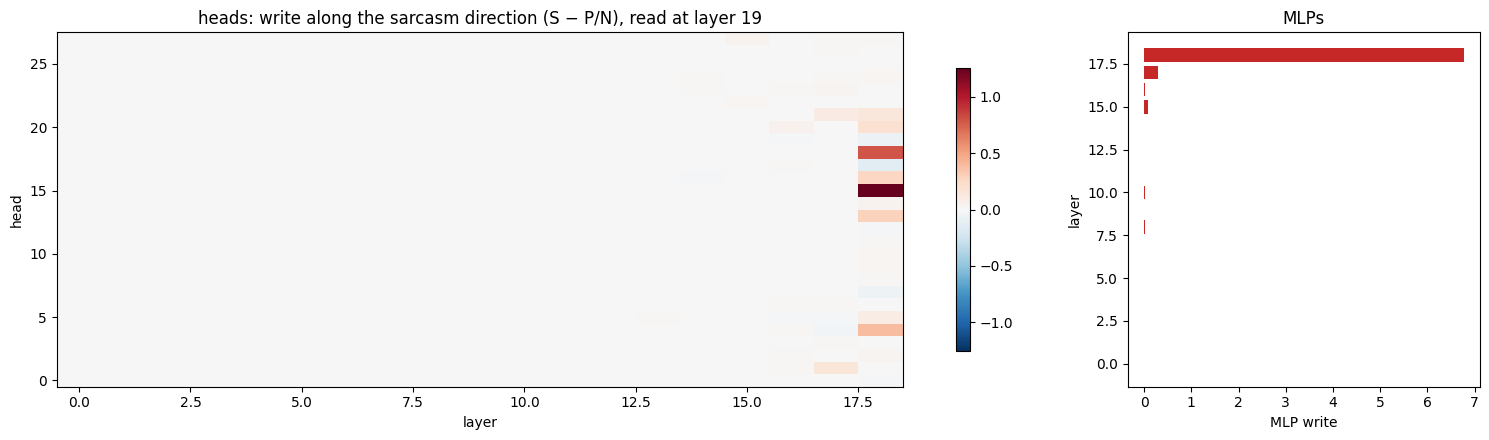

In [8]:
rng = np.random.default_rng(2)
tids = rng.choice(df[df.group == "discovery"].triple_id.unique(), N_WRITE, replace=False)
w_idx = list(df.index[df.triple_id.isin(tids)])
u = V[L_STAR] / np.linalg.norm(V[L_STAR])
HW, MW = cached(f"writes_L{L_STAR}_n{N_WRITE}", lambda: component_writes(model, tok, [IDS[i] for i in w_idx], u, L_STAR), sub=SUB)

# sanity: the parts add up to the residual stream projection
total = X[w_idx, 0].astype(np.float32) @ u + HW.sum((1, 2)) + MW.sum(1)
direct = X[w_idx, L_STAR].astype(np.float32) @ u
print(f"sanity: corr(sum of parts, residual) = {np.corrcoef(total, direct)[0, 1]:.4f}, max |diff| = {np.abs(total - direct).max():.3f}")

cw = df.loc[w_idx].condition.values
score_h = HW[cw == "S"].mean(0) - HW[cw != "S"].mean(0)        # [L_STAR, H]
score_m = MW[cw == "S"].mean(0) - MW[cw != "S"].mean(0)        # [L_STAR]
gap = direct[cw == "S"].mean() - direct[cw != "S"].mean()
print(f"S - P/N gap along the direction at layer {L_STAR}: {gap:.2f} (embedding part {(X[w_idx, 0].astype(np.float32) @ u)[cw == 'S'].mean() - (X[w_idx, 0].astype(np.float32) @ u)[cw != 'S'].mean():.2f})")

def in_circuit(path, l, h=None):
    p = os.path.join(results_dir(""), path)
    if not os.path.exists(p):
        return None
    m = np.load(p)
    row = 1 + l * H + h if h is not None else 1 + L * H + l
    return bool(m[row].any())
C2 = f"02_acdc/{TAG}/v3b/acdc_mask_tau0.0.npy"
C1 = f"02_acdc/{TAG_MODEL}/v3b/acdc_mask_tau0.0.npy"
rows = [dict(component=f"a{l}.h{h}", layer=l, write=score_h[l, h]) for l in range(L_STAR) for h in range(H)]
rows += [dict(component=f"m{l}", layer=l, write=score_m[l]) for l in range(L_STAR)]
W = pd.DataFrame(rows)
W["share of gap"] = W.write / gap
W["in ACDC v2"] = [in_circuit(C2, r.layer, int(r.component.split(".h")[1]) if ".h" in r.component else None) for r in W.itertuples()]
W["in ACDC v1"] = [in_circuit(C1, r.layer, int(r.component.split(".h")[1]) if ".h" in r.component else None) for r in W.itertuples()]
W = W.reindex(W.write.abs().sort_values(ascending=False).index).reset_index(drop=True)
display(W.head(25).round(3))
top = W.head(25)
print(f"top-25 writers: {int(top['in ACDC v2'].sum())} in the ACDC v2 circuit, {int(top['in ACDC v1'].sum())} in the v1 circuit")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [3, 1]})
lim = np.abs(score_h).max()
im = axes[0].imshow(score_h.T, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim, origin="lower")
axes[0].set_xlabel("layer"); axes[0].set_ylabel("head"); axes[0].set_title(f"heads: write along the sarcasm direction (S − P/N), read at layer {L_STAR}")
plt.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].barh(range(L_STAR), score_m, color=["#C62828" if s > 0 else "#1565C0" for s in score_m])
axes[1].set_xlabel("MLP write"); axes[1].set_ylabel("layer"); axes[1].set_title("MLPs")
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "who_writes.png"), dpi=150); plt.show()

## 5 · Your own sentences

Score = position on the sarcasm direction at layer `L_STAR`: 0 = like an average non-sarcastic discovery prompt,
1 = like an average sarcastic one. Next to it the full model's answer. The histogram shows the scores of the
held-out prompts for reference.

score +1.29  |  full model d =  +2.37 -> Yes  |  My house burned down. This is the happiest day of my life.
score +0.07  |  full model d = -16.41 -> No   |  My house burned down. This is the worst day of my life.
score -0.95  |  full model d =  -8.53 -> No   |  I won a free trip to Paris. This is the happiest day of my life.
score +0.66  |  full model d =  +4.56 -> Yes  |  I got to work on my weekend. What a fantastic way to relax.
score -0.48  |  full model d =  -6.55 -> No   |  I got to sleep in all weekend. What a fantastic way to relax.
score +1.34  |  full model d =  +1.50 -> Yes  |  My dog died today. This is the best news I had all day.
score +0.30  |  full model d =  +5.42 -> Yes  |  Oh great, another Monday.
score +0.91  |  full model d = +13.30 -> Yes  |  Thanks a lot for nothing.


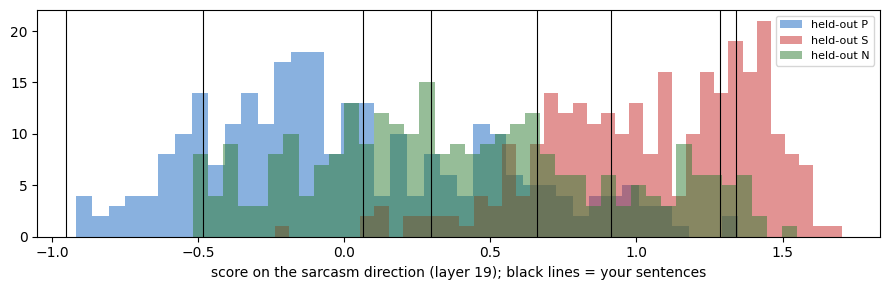

In [9]:
SENTENCES = [
    "My house burned down. This is the happiest day of my life.",
    "My house burned down. This is the worst day of my life.",
    "I won a free trip to Paris. This is the happiest day of my life.",
    "I got to work on my weekend. What a fantastic way to relax.",
    "I got to sleep in all weekend. What a fantastic way to relax.",
    "My dog died today. This is the best news I had all day.",
    "Oh great, another Monday.",
    "Thanks a lot for nothing.",
]
template = df.prompt.iloc[0].replace(df.text.iloc[0], "{}")
ids_own = [tok(chat_text(tok, template.format(s)), add_special_tokens=False)["input_ids"] for s in SENTENCES]
Xo, Do = collect_resid(model, tok, ids_own, progress=False)

proj = lambda Z: Z.astype(np.float32) @ u
p_all = proj(X[:, L_STAR])
lo, hi = p_all[TRAIN & (df.condition != "S").values].mean(), p_all[TRAIN & (df.condition == "S").values].mean()
score = lambda p: (p - lo) / (hi - lo)
for s, p, d in zip(SENTENCES, proj(Xo[:, L_STAR]), Do):
    print(f"score {score(p):+5.2f}  |  full model d = {d:+6.2f} -> {'Yes' if d > 0 else 'No '}  |  {s}")

fig, ax = plt.subplots(figsize=(9, 3))
for c, col in [("P", "#1565C0"), ("S", "#C62828"), ("N", "#2E7D32")]:
    m = (~TRAIN) & (df.condition == c).values
    ax.hist(score(p_all[m]), bins=40, alpha=0.5, color=col, label=f"held-out {c}")
for p in proj(Xo[:, L_STAR]):
    ax.axvline(score(p), c="black", lw=0.8)
ax.set_xlabel(f"score on the sarcasm direction (layer {L_STAR}); black lines = your sentences"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "own_sentences.png"), dpi=150); plt.show()

## Save

In [10]:
d = results_dir(SUB)
for name, acc in PROBE.items():
    pd.DataFrame(acc, columns=GROUPS).to_csv(os.path.join(d, f"probe_{name.split(' ')[0]}.csv"), index_label="layer")
ST.to_csv(os.path.join(d, "steering.csv"), index=False)
W.to_csv(os.path.join(d, "who_writes.csv"), index=False)
np.save(os.path.join(d, f"sarcasm_direction_L{L_STAR}.npy"), V[L_STAR])
json.dump(dict(model=MODEL, data=DATA, L_STAR=L_STAR,
               probe_sarcasm_at_L_STAR=dict(zip(GROUPS, PROBE["sarcasm (S vs P, N)"][L_STAR].round(4).tolist())),
               sentiment_test_at_L_STAR={k: dict(zip(GROUPS, v[L_STAR].round(4).tolist())) for k, v in SENT.items()},
               cos_at_L_STAR=dict(phrase=float(COS[L_STAR, 0]), situation=float(COS[L_STAR, 1]))),
          open(os.path.join(d, "summary.json"), "w"), indent=1)
print("saved to", d)

saved to /content/drive/MyDrive/sarcasm/03a_direction/Qwen2.5-7B-Instruct_data-v2
